In [13]:
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
import koreanize_matplotlib

In [2]:
file = "/Users/youngjinseo/Desktop/데이터분석프로젝트/Instagram_Analytics.csv"
df = pd.read_csv(file)

df.head(5)

,post_id,account_id,account_type,follower_count,media_type,content_category,traffic_source,has_call_to_action,post_datetime,post_date,...,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count,performance_bucket_label
0,IG0000001,7,brand,3551,reel,Technology,Home Feed,1,2024-11-30 06:00:00,2024-11-30,...,5,7,34,4327,6230,0.0385,899,100,7,medium
1,IG0000002,20,creator,31095,image,Fitness,Hashtags,1,2025-08-15 15:00:00,2025-08-15,...,10,21,68,7451,8268,0.0663,805,122,5,viral
2,IG0000003,15,brand,8167,reel,Beauty,Reels Feed,0,2025-09-11 16:00:00,2025-09-11,...,2,1,22,1639,2616,0.0531,758,115,8,high
3,IG0000004,11,creator,9044,carousel,Music,External,0,2025-09-18 03:00:00,2025-09-18,...,0,7,0,2877,3171,0.0309,402,115,7,medium
4,IG0000005,8,creator,15986,reel,Technology,Profile,0,2025-03-21 09:00:00,2025-03-21,...,8,5,21,5350,8503,0.0221,155,112,9,low


## 데이터 탐색 

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29999 entries, 0 to 29998
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   post_id                   29999 non-null  str    
 1   account_id                29999 non-null  int64  
 2   account_type              29999 non-null  str    
 3   follower_count            29999 non-null  int64  
 4   media_type                29999 non-null  str    
 5   content_category          29999 non-null  str    
 6   traffic_source            29999 non-null  str    
 7   has_call_to_action        29999 non-null  int64  
 8   post_datetime             29999 non-null  str    
 9   post_date                 29999 non-null  str    
 10  post_hour                 29999 non-null  int64  
 11  day_of_week               29999 non-null  str    
 12  likes                     29999 non-null  int64  
 13  comments                  29999 non-null  int64  
 14  shares           

## 릴스, 이미지, 캐러셀 중 참여율 분포가 높은 유형은 무엇인가?

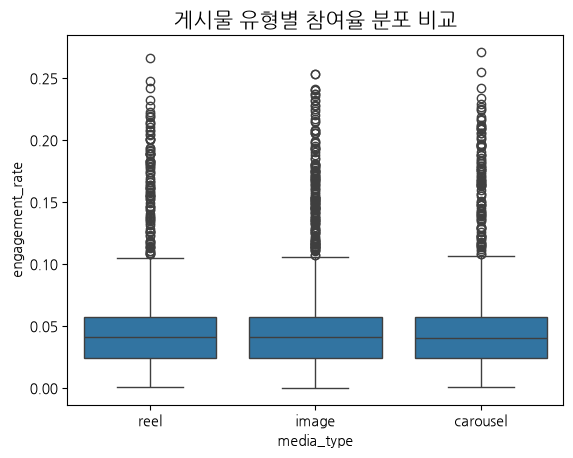

In [14]:
sns.boxplot(data = df, x = 'media_type', y = 'engagement_rate')
plt.title("게시물 유형별 참여율 분포 비교",fontsize = 15 )
plt.show()

## 어떤 콘텐츠 카테고리가 상대적으로 높은 참여율을 보이는가?

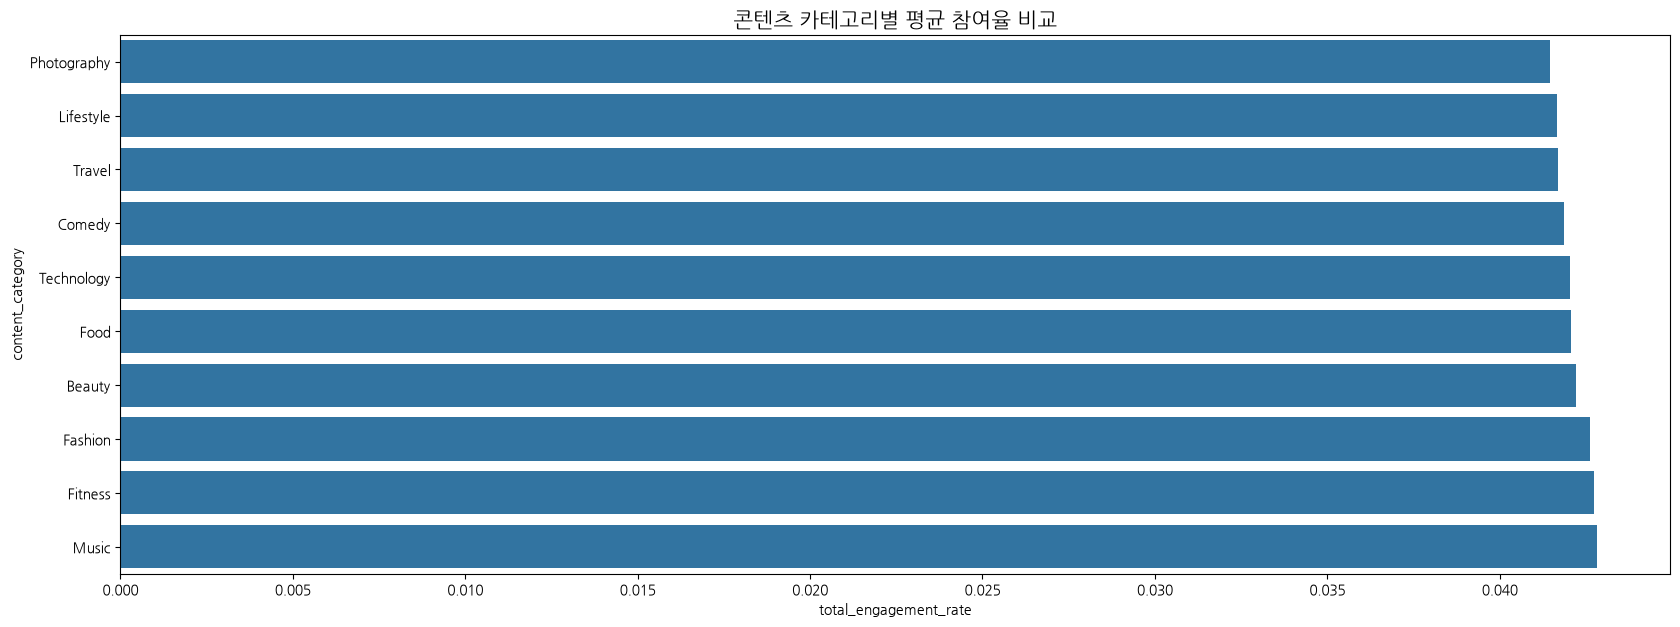

In [15]:
mf = (
    df.groupby('content_category').agg(total_engagement_rate = ('engagement_rate','mean'))
        .sort_values(['total_engagement_rate'] )
        .reset_index()
)

plt.figure(figsize = (20,7))
sns.barplot(data  = mf, y = 'content_category',  x = 'total_engagement_rate')
plt.title("콘텐츠 카테고리별 평균 참여율 비교",fontsize = 15 )
plt.show()

## 참여율과 신규 팔로워 증가는 어떤 관계인가?

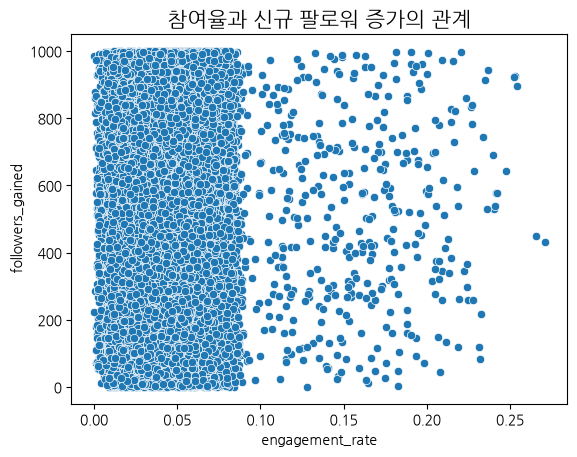

In [16]:
sns.scatterplot(data = df, x = 'engagement_rate', y = 'followers_gained')
plt.title('참여율과 신규 팔로워 증가의 관계', fontsize  = 15)
plt.show()

## 어떤 요일과 시간대에서 높은 참여율이 관찰되는가?

In [7]:
mf = df[['day_of_week','post_hour','engagement_rate']]
mf

,day_of_week,post_hour,engagement_rate
0,Saturday,6,0.0385
1,Friday,15,0.0663
2,Thursday,16,0.0531
3,Thursday,3,0.0309
4,Friday,9,0.0221
...,...,...,...
29994,Wednesday,10,0.0032
29995,Monday,15,0.0209
29996,Monday,10,0.0558
29997,Saturday,19,0.0333


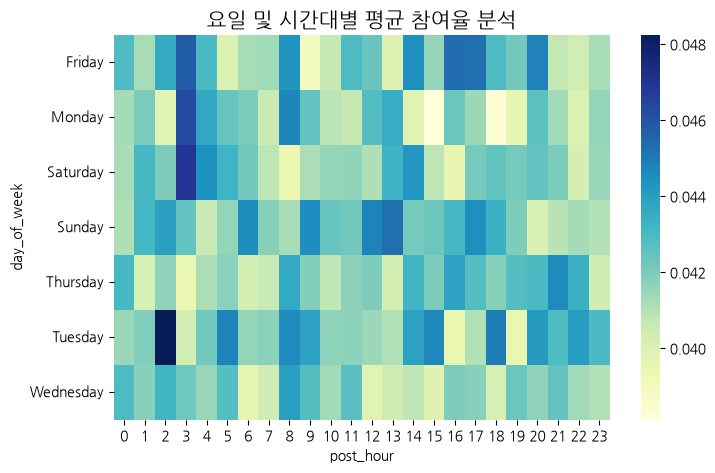

In [17]:
time_pivot = df.pivot_table(
    index = 'day_of_week',
    columns = 'post_hour',
    values = 'engagement_rate',
    aggfunc = 'mean'
)

plt.figure(figsize = (8,5))
sns.heatmap(time_pivot, cmap="YlGnBu")
plt.title('요일 및 시간대별 평균 참여율 분석', fontsize = 15)
plt.show()

## CTA가 있는 게시물과 없는 게시물의 성과 분포는 어떻게 다른가?

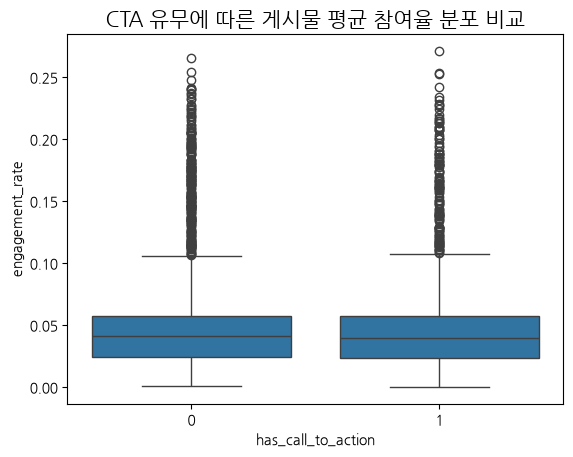

In [18]:
sns.boxplot(data = df, x = 'has_call_to_action', y = 'engagement_rate')
plt.title('CTA 유무에 따른 게시물 평균 참여율 분포 비교', fontsize = 15)
plt.show()

In [10]:
from scipy.stats import mannwhitneyu

In [11]:
a = df.loc[
    df['has_call_to_action'] == False, 
    'engagement_rate'
].dropna()

b = df.loc[
    df['has_call_to_action'] == True, 
    'engagement_rate'
].dropna()


stat, p_value = mannwhitneyu(
    a, b,
    alternative="two-sided"
)

print("A 그룹 평균:", a.mean())
print("B 그룹 평균:", b.mean())
print("평균 차이(B-A):", b.mean() - a.mean())
print("p-value:", p_value)

A 그룹 평균: 0.04223150593775593
B 그룹 평균: 0.04187539902513619
평균 차이(B-A): -0.0003561069126197386
p-value: 0.04918429928014343
